In [46]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from matplotlib import cm
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe
from scipy.spatial.distance import jaccard, euclidean, cosine
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster import hierarchy
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**7/13/22 kmeans and hierarchical clustering of terms**

In [3]:
#load data
descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220713.genedescriptorooe.sig.hdf5'
descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
term_sig_log2ooe = descriptor_hdf5['sig_term_roi_log2ooe'][:]
term_sig_counts = descriptor_hdf5['sig_term_roi_counts'][:]
descriptor_hdf5.close()

In [3]:
term_sig_log2ooe[:, np.sum(term_sig_log2ooe, axis=0)!=0].shape

(87351, 4743)

In [53]:
kmeans = KMeans(n_clusters=20, 
               init='random', 
               random_state=3,
               algorithm='elkan').fit(term_sig_log2ooe[:, np.sum(term_sig_log2ooe, axis=0)!=0].T)

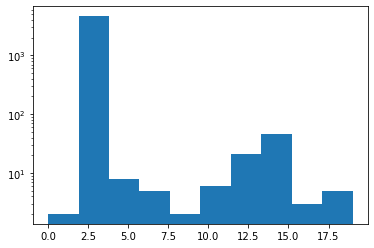

In [54]:
plt.hist(kmeans.labels_)
plt.yscale('log')

In [7]:
agglo = AgglomerativeClustering(
    n_clusters=5,
    compute_full_tree=False,
    linkage='ward'
).fit(term_sig_log2ooe[:, np.where(np.sum(term_sig_log2ooe, axis=0)!=0)[0][:1000]].T)
agglo.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [8]:
agglo = AgglomerativeClustering(
    n_clusters=5,
    compute_full_tree=False,
    linkage='average'
).fit(term_sig_log2ooe[:, np.where(np.sum(term_sig_log2ooe, axis=0)!=0)[0][:1000]].T)
agglo.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [9]:
agglo = AgglomerativeClustering(
    n_clusters=5,
    compute_full_tree=False,
    linkage='complete'
).fit(term_sig_log2ooe[:, np.where(np.sum(term_sig_log2ooe, axis=0)!=0)[0][:1000]].T)
agglo.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [10]:
agglo = AgglomerativeClustering(
    n_clusters=5,
    compute_full_tree=False,
    linkage='single'
).fit(term_sig_log2ooe[:, np.where(np.sum(term_sig_log2ooe, axis=0)!=0)[0][:1000]].T)
agglo.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [17]:
DBSCAN
dbscan = DBSCAN(
    eps=0.9,
    min_samples=5,
    metric='cosine'
).fit(term_sig_log2ooe[:, np.where(np.sum(term_sig_log2ooe, axis=0)!=0)[0][:1000]].T)
dbscan.labels_

array([-1, -1, -1, -1,  0, -1, -1,  6, -1, -1,  0, -1, -1, -1,  0, -1, -1,
       -1,  0,  0, -1,  0, -1,  0, -1,  0, -1,  0, -1, -1, -1,  0,  1, -1,
       -1,  0, -1,  0, -1,  0, -1, -1,  0,  0, -1, -1,  0,  0, -1, -1, -1,
       -1, -1, -1, -1, -1, -1,  0, -1,  0,  0,  0, -1,  0, -1, -1,  0,  0,
       -1, -1, -1,  1, -1,  0, -1,  0,  0, -1,  1, -1, -1,  0, -1, -1, -1,
       -1, -1, -1, -1, -1,  0,  0,  0, -1,  0, -1,  0,  0,  0, -1, -1, -1,
       -1,  0, -1,  0, -1, -1, -1, -1, -1,  0,  0,  0, -1, -1, -1,  0, -1,
       -1, -1, -1, -1, -1,  0, -1, -1,  0, -1,  0,  0, -1,  0, -1, -1, -1,
       -1, -1,  0, -1, -1, -1, -1, -1,  4,  0,  0, -1,  0, -1,  0,  0, -1,
        2,  6, -1, -1, -1,  0,  0, -1, -1,  1, -1,  0, -1, -1, -1,  0,  0,
       -1, -1, -1,  0, -1,  0,  0, -1,  0, -1, -1, -1,  0, -1,  0, -1, -1,
       -1, -1, -1, -1,  0, -1, -1, -1, -1, -1, -1, -1,  0,  0, -1, -1, -1,
       -1, -1, -1,  0, -1,  0,  0, -1, -1, -1,  0,  0, -1, -1, -1,  0,  0,
        0,  3, -1,  3, -1

In [34]:
#try mapping with just nonzero vectors
# term_cosine_sim_m = cosine_similarity(term_sig_log2ooe[:, np.sum(term_sig_log2ooe, axis=0)!=0].T)
term_cosine_sim_m = cosine_similarity(term_sig_log2ooe.T)

In [35]:
term_cosine_sim_m.shape

(5780, 5780)

In [36]:
ward_cluster = hierarchy.ward(term_cosine_sim_m)

In [37]:
ward_cluster_reordered = hierarchy.optimal_leaf_ordering(ward_cluster, term_cosine_sim_m)

In [38]:
term_order = hierarchy.leaves_list(ward_cluster_reordered)

In [71]:
term_order

array([1251, 1489, 3599, ..., 5291, 5114,  520], dtype=int32)

In [107]:
np.where(np.sum(term_sig_log2ooe, axis=0)==0)[0]

array([   1,   10,   12, ..., 5775, 5777, 5779])

In [101]:
x = []
for i in np.where(np.sum(term_sig_log2ooe, axis=0)==0)[0]:
    x.append(np.where(term_order==i)[0][0])
x = np.array(x)

In [105]:
len(x)

1037

In [108]:
2728 - 3764

-1036

In [104]:
describe(x)

DescribeResult(nobs=1037, minmax=(2728, 3764), mean=3246.0, variance=89700.5, skewness=0.0, kurtosis=-1.2000022317941392)

In [55]:
colors = cm.get_cmap('viridis', len(term_order)).colors

In [56]:
colors

array([[0.267004, 0.004874, 0.329415, 1.      ],
       [0.267004, 0.004874, 0.329415, 1.      ],
       [0.267004, 0.004874, 0.329415, 1.      ],
       ...,
       [0.993248, 0.906157, 0.143936, 1.      ],
       [0.993248, 0.906157, 0.143936, 1.      ],
       [0.993248, 0.906157, 0.143936, 1.      ]])

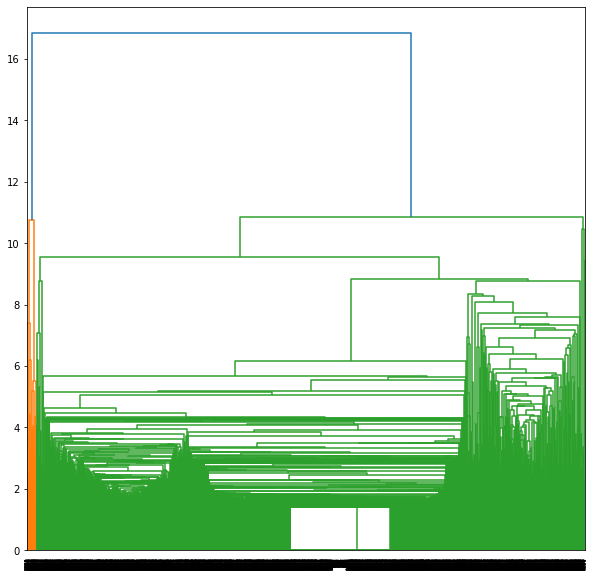

In [45]:
fig = plt.figure(figsize=(10,10))
dendrogram = hierarchy.dendrogram(ward_cluster_reordered)

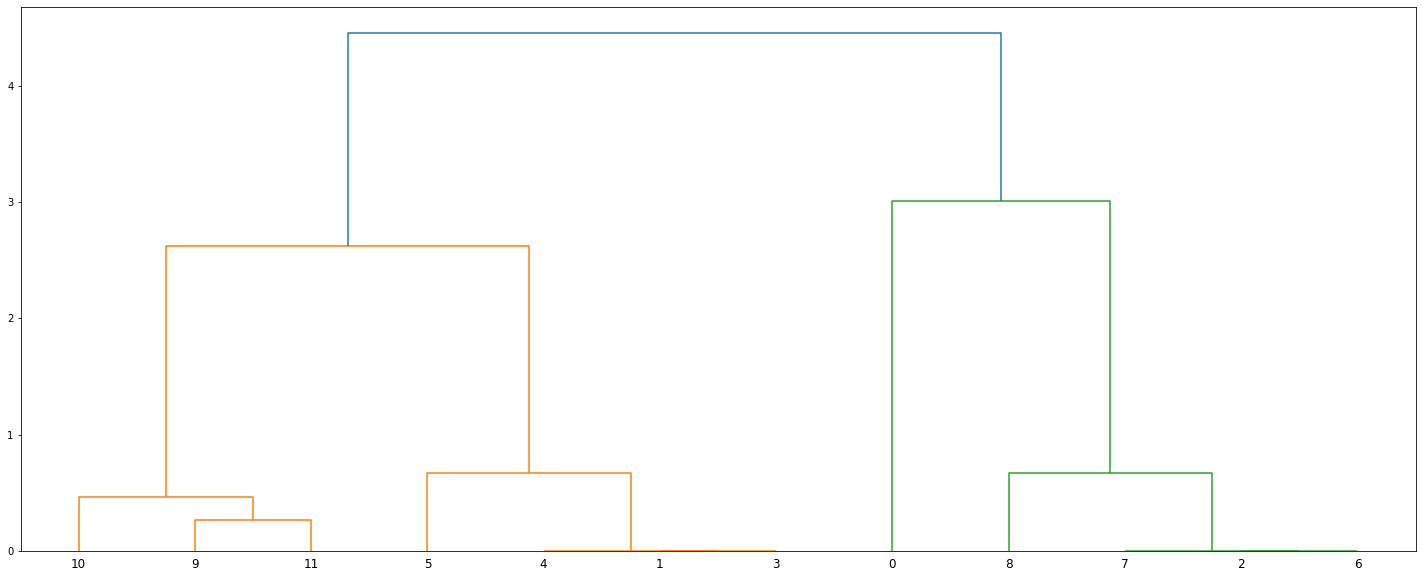

In [69]:
X = [[0, 0], 
     [0, 1], 
     [1, 0],
     [0, 4], 
     [0, 3], 
     [1, 4],
     [4, 0], 
     [3, 0], 
     [4, 1],
     [4, 4], 
     [3, 4], 
     [4, 3]]
Z = hierarchy.ward(cosine_similarity(X))
z0 = cosine_similarity(X)
fig = plt.figure(figsize=(25, 10))
dn = hierarchy.dendrogram(Z)
plt.show()

In [70]:
hierarchy.leaves_list(Z)

array([10,  9, 11,  5,  4,  1,  3,  0,  8,  7,  2,  6], dtype=int32)

In [65]:
np.argsort(-z0[10])

array([10,  9, 11,  5,  1,  3,  4,  8,  2,  6,  7,  0])

**7/13/22 finding significant gene descriptor terms**

In [2]:
#load data
descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.genedescriptorooe.hdf5'
descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
term_full_ooe = descriptor_hdf5['term_roi_ooe'][:]
term_full_counts = descriptor_hdf5['term_roi_counts'][:]
descriptor_hdf5.close()

In [21]:
def find_significance_for_region(total_term_counts, region):
    region_counts = term_full_counts[region]
    terms_inds_to_test = np.where(region_counts!=0)[0]
    sig_pa = np.array([False]*len(region_counts))
    for term in terms_inds_to_test:
        term_count_in_region = region_counts[term]
        not_term_count_in_region = np.sum(region_counts) - term_count_in_region
        term_count_in_not_region = np.sum(term_full_counts[:, term]) - term_count_in_region
        not_term_count_in_not_region = total_term_counts - term_count_in_region - not_term_count_in_region - term_count_in_not_region
        #calculating p value from fisher exact test
        conting = [[term_count_in_region, not_term_count_in_region], 
               [term_count_in_not_region, not_term_count_in_not_region]]
        odds, pval = fisher_exact(conting, alternative='greater')
        #bonferroni correction
        if pval < (0.05 / len(terms_inds_to_test)):
            sig_pa[term] = True
    return sig_pa

In [15]:
t = time.time()
for region in range(10):
    region_counts = term_full_counts[region]
    terms_inds_to_test = np.where(region_counts!=0)[0]
    sig_pa = np.array([False]*len(region_counts))
    
time.time()-t

0.0051043033599853516

In [22]:
num_cpus=1

total_term_counts = np.sum(term_full_counts)
t = time.time()
#split on cluster and find significant terms
print('Determining significance for terms in each region...', flush=True)
func = partial(find_significance_for_region, total_term_counts)
with closing(Pool(num_cpus)) as pool:
    sig_pa = pool.map(func, np.arange(len(term_full_counts))[:10])
pool.join()
print(time.time()-t)
sig_pa = np.array(sig_pa)

Determining significance for terms in each region...
0.8764321804046631


In [ ]:
#keep only ooe values that are also significant
term_sig_ooe = np.where(sig_pa, np.log2(term_full_ooe[:1000]), 0)

**7/12/22 fixing issue with pool**

In [20]:
#making a dictionary to map genes to regions. Each gene will map to an arrray of regions
def map_genes_to_regions(all_regions_gene_ids):
    gene2region = {}
    for genes, region in zip(all_regions_gene_ids, range(len(all_regions_gene_ids))):
        if len(genes) > 1:
            for gene in genes:
                if gene not in gene2region:
                    gene2region[gene] = np.array([region])
                else:
                    gene2region[gene] = np.append(gene2region[gene], [region])
    return gene2region

#making dictionaries to map a gene to similar genes and corresponding scores
def map_genes_to_genes(metric_top1000):
    gene2genes = {}
    gene2scores = {}
    for row in metric_top1000:
        gene0 = row[0]
        gene1 = row[1]
        score = int(row[2])
        if gene0 not in gene2genes:
            gene2genes[gene0] = np.array([gene1])
            gene2scores[gene0] = np.array([score])
        else:
            gene2genes[gene0] = np.append(gene2genes[gene0], [gene1])
            gene2scores[gene0] = np.append(gene2scores[gene0], [score])
    return gene2genes, gene2scores

#converting string scores to a num_regions x num_saved_recommended_regions matrix
def create_sim_matrix(all_regions_gene_ids, metric_top1000, gene2region, gene2genes, gene2scores, starting_region):
    genes = all_regions_gene_ids[starting_region]
    #if there are no genes
    if len(genes) == 0:
        region_scores_to_m = np.zeros(1000, dtype=int)
        similar_regions_to_m = np.arange(1000)
        origin_gene_tracker_to_m = np.array(['nan']*1000)
        destination_gene_tracker_to_m = np.array(['nan']*1000)
    #if there is at least 1 gene
    else:
        region_scores_init = np.array([], dtype=int)
        similar_genes_init = np.array([])
        origin_gene_tracker_init = np.array([])
        for gene in genes:
            #finding similar genes/scores based on origin gene
            region_scores_init = np.append(region_scores_init, gene2scores[gene])
            similar_genes_init = np.append(similar_genes_init, gene2genes[gene])
            origin_gene_tracker_init = np.append(origin_gene_tracker_init, np.array([gene]*len(gene2scores[gene])))

        region_scores = np.array([], dtype=int)
        similar_regions = np.array([], dtype=int)
        origin_gene_tracker = np.array([])
        destination_gene_tracker = np.array([])
        for gene, score, origin_gene in zip(similar_genes_init, region_scores_init, origin_gene_tracker_init):
            #if gene in some region, add scores/regions to final arrays
            if gene in gene2region:
                gene_regions = gene2region[gene]
                similar_regions = np.append(similar_regions, gene_regions)
                region_scores = np.append(region_scores, np.array([score]*len(gene_regions)))
                origin_gene_tracker = np.append(origin_gene_tracker, np.array([origin_gene]*len(gene_regions)))
                destination_gene_tracker = np.append(destination_gene_tracker, np.array([gene]*len(gene_regions)))

        #sort scores
        sort_order = np.argsort(-region_scores)
        region_scores = region_scores[sort_order]
        similar_regions = similar_regions[sort_order]
        origin_gene_tracker = origin_gene_tracker[sort_order]
        destination_gene_tracker = destination_gene_tracker[sort_order]

        #find first occurance/score of each region
        region_scores_to_m = np.array([], dtype=int)
        similar_regions_to_m = np.array([], dtype=int)
        origin_gene_tracker_to_m = np.array([])
        destination_gene_tracker_to_m = np.array([])
        for region, score, original_gene, destination_gene in zip(similar_regions, region_scores, origin_gene_tracker, destination_gene_tracker):
            if ((region not in similar_regions_to_m) & (region != starting_region)):
                similar_regions_to_m = np.append(similar_regions_to_m, [region])
                region_scores_to_m = np.append(region_scores_to_m, [score])
                origin_gene_tracker_to_m = np.append(origin_gene_tracker_to_m, [original_gene])
                destination_gene_tracker_to_m = np.append(destination_gene_tracker_to_m, [destination_gene])

        #take top 1000 regions/scores
        region_scores_to_m = region_scores_to_m[:1000]
        similar_regions_to_m = similar_regions_to_m[:1000]
        origin_gene_tracker_to_m = origin_gene_tracker_to_m[:1000]
        destination_gene_tracker_to_m = destination_gene_tracker_to_m[:1000]

        arr_len = len(region_scores_to_m)
        if arr_len < 1000:
            region_scores_to_m = np.append(region_scores_to_m, np.zeros(1000-arr_len, dtype=int))
            similar_regions_to_m = np.append(similar_regions_to_m, np.array([starting_region]*(1000-arr_len)))
            origin_gene_tracker_to_m = np.append(origin_gene_tracker_to_m, np.array(['nan']*(1000-arr_len)))
            destination_gene_tracker_to_m = np.append(destination_gene_tracker_to_m, np.array(['nan']*(1000-arr_len)))

    return np.append(np.append(np.append(region_scores_to_m.astype(str), similar_regions_to_m.astype(str)), origin_gene_tracker_to_m), destination_gene_tracker_to_m)

#ranking and scaling data
def scale_data(data, max_poss):
    data_to_rank = data[data!=0]
    max_obs = np.max(data_to_rank)
    rank_data = rankdata(data_to_rank, method='average')
    rank_data = rank_data/(len(data_to_rank))
    rank_data = rank_data * max_obs/max_poss

    original_data_shape = data.shape
    data = data.astype(float).flatten()
    np.put(data, np.where(data!=0)[0], rank_data)
    data = data.reshape(original_data_shape)
    return data

In [22]:
metric_path = '/home/ctrader/region_similarity/data/STRING/9606.protein.links.v11.5.coexpression_human_transferred_max.all_associations.CT20220711.txt'
gene_id_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.geneidmapped.bed'
# out_path
# out_path_original_genes
num_cpus = 1



print('Loading data...', flush=True)
# #load metric data
# f = open(metric_path, 'r')
# metric_top1000 = []
# for line in f.readlines():
#     line = line.strip().split('\t')
#     metric_top1000.append(line)
# metric_top1000 = np.array(metric_top1000)
# f.close()

# #find the mapped gene ids that have metric associations listed
# unique_gene_codes_with_associations = set(metric_top1000[:, 0])

# f = open(gene_id_mapped_path, 'r')
# all_regions_gene_ids = []
# for line in f.readlines():
#     region_gene_ids = []
#     geneids = re.split('\t|;|\|', line.strip())[3:]
#     for geneid in geneids:
#         if geneid in unique_gene_codes_with_associations:
#             region_gene_ids.append(geneid)
#     all_regions_gene_ids.append(region_gene_ids)
# f.close()

print('Mapping genes to regions, genes, and scores...', flush=True)
# #making a dictionary to map genes to regions. Each gene will map to an arrray of regions
# gene2region = map_genes_to_regions(all_regions_gene_ids)

#making dictionaries to map a gene to similar genes and corresponding scores
# gene2genes, gene2scores = map_genes_to_genes(metric_top1000)

#split on cluster and find similar regions matrix based on STING metric scores
print('Finding similar regions...', flush=True)
func = partial(create_sim_matrix, all_regions_gene_ids, metric_top1000, gene2region, gene2genes, gene2scores)
with closing(Pool(num_cpus)) as pool:
    top_1000_similar_inds = pool.map(func, np.arange(len(all_regions_gene_ids)))
pool.join()
top_1000_similar_inds = np.array(top_1000_similar_inds)
#unsplit results from pool function
top_1000_region_scores = top_1000_similar_inds[:, :1000].astype(int)
top_1000_similar_regions = top_1000_similar_inds[:, 1000:2000].astype(int)
top_1000_origin_gene_tracker = top_1000_similar_inds[:, 2000:3000]
top_1000_destination_gene_tracker = top_1000_similar_inds[:, 3000:]
del top_1000_similar_inds


Loading data...
Mapping genes to regions, genes, and scores...
Finding similar regions...


Process ForkPoolWorker-573:
Traceback (most recent call last):
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/pool.py", line 114, in worker
    task = get()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/queues.py", line 358, in get
    return _ForkingPickler.loads(res)
_pickle.UnpicklingError: invalid load key, '\x00'.
Process ForkPoolWorker-574:
Traceback (most recent call last):
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/ctrader

_pickle.UnpicklingError: invalid load key, '\x00'.
Process ForkPoolWorker-634:
Traceback (most recent call last):
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/pool.py", line 114, in worker
    task = get()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/queues.py", line 358, in get
    return _ForkingPickler.loads(res)
_pickle.UnpicklingError: invalid load key, '\x00'.
Process ForkPoolWorker-635:
Traceback (most recent call last):
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 108, in run
    self._target

  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/queues.py", line 358, in get
    return _ForkingPickler.loads(res)
_pickle.UnpicklingError: invalid load key, '\x00'.
Process ForkPoolWorker-695:
Traceback (most recent call last):
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/pool.py", line 114, in worker
    task = get()
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/queues.py", line 358, in get
    return _ForkingPickler.loads(res)
_pickle.UnpicklingError: invalid load key, '\x00'.
Process ForkPoolWorker-561:
Traceback (most recent call last):
  File "/home/ctrader/.conda/envs/lightfm/lib/python3.8/multiprocessing/process.py", line 315, in _boot

KeyboardInterrupt: 

**7/5/22 Mapping gene ids to scores and returning top 1000 regions for each region**

In [28]:
metric_path = '/home/ctrader/region_similarity/data/STRING/9606.protein.links.v11.5.coexpression.top_1000_associations.CT20220705.txt'
f = open(metric_path, 'r')

metric_top1000 = []
for line in f.readlines():
    line = line.strip().split('\t')
    metric_top1000.append(line)
metric_top1000 = np.array(metric_top1000)

f.close()

In [33]:
#find the mapped gene ids that have metric associations listed
unique_gene_codes_with_associations = set(metric_top1000[:, 0])

gene_id_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220705.geneidmapped.bed'
f = open(gene_id_mapped_path, 'r')

all_regions_gene_ids = []
for line in f.readlines():
    region_gene_ids = []
    geneids = re.split('\t|;|\|', line.strip())[3:]
    for geneid in geneids:
        if geneid in unique_gene_codes_with_associations:
            region_gene_ids.append(geneid)
    all_regions_gene_ids.append(region_gene_ids)
f.close()

In [203]:
#making a dictionary to map genes to regions. Each gene will map to an arrray of regions
gene2region = {}
for genes, region in zip(all_regions_gene_ids, range(len(all_regions_gene_ids))):
    if len(genes) > 1:
        for gene in genes:
            if gene not in gene2region:
                gene2region[gene] = np.array([region])
            else:
                gene2region[gene] = np.append(gene2region[gene], [region])

In [183]:
#creating an n_regions x 1000 similarity matrix
region_scores_all_regions = []
similar_regions_all_regions = []
origin_gene_all_regions = []

for genes, starting_region in zip(all_regions_gene_ids, range(len(all_regions_gene_ids))):
    #if there are no genes
    if len(genes) == 0:
        region_scores_to_m = np.zeros(1000, dtype=int)
        similar_regions_to_m = np.arange(1000)
        origin_gene_tracker_to_m = np.array(['nan']*1000)
    #if there is at least 1 gene
    else:
        region_scores_init = np.array([], dtype=int)
        similar_genes_init = np.array([])
        origin_gene_tracker_init = np.array([])
        for gene in genes:
            #finding similar genes/scores based on origin gene
            gene_similar_genes = metric_top1000[metric_top1000[:, 0]==gene]
            region_scores_init = np.append(region_scores, gene_similar_genes[:, 2].astype(int))
            similar_genes_init = np.append(similar_genes, gene_similar_genes[:, 1])
            origin_gene_tracker_init = np.append(origin_gene_tracker_init, np.array([gene]*len(gene_similar_genes)))

        region_scores = np.array([], dtype=int)
        similar_regions = np.array([], dtype=int)
        origin_gene_tracker = np.array([])
        for gene, score, origin_gene in zip(similar_genes_init, region_scores_init, origin_gene_tracker_init):
            #if gene in some region, add scores/regions to final arrays
            if gene in gene2region:
                gene_regions = gene2region[gene]
                similar_regions = np.append(similar_regions, gene_regions)
                region_scores = np.append(region_scores, np.array([score]*len(gene_regions)))
                origin_gene_tracker = np.append(origin_gene_tracker, np.array([origin_gene]*len(gene_regions)))
        
        #sort scores
        sort_order = np.argsort(-region_scores)
        region_scores = region_scores[sort_order]
        similar_regions = similar_regions[sort_order]
        origin_gene_tracker = origin_gene_tracker[sort_order]
        
        #find first occurance/score of each region
        region_scores_to_m = np.array([], dtype=int)
        similar_regions_to_m = np.array([], dtype=int)
        origin_gene_tracker_to_m = np.array([])
        for region, score, original_gene in zip(similar_regions, region_scores, origin_gene_tracker):
            if ((region not in similar_regions_to_m) & (region != starting_region)):
                similar_regions_to_m = np.append(similar_regions_to_m, [region])
                region_scores_to_m = np.append(region_scores_to_m, [score])
                origin_gene_tracker_to_m = np.append(origin_gene_tracker_to_m, [original_gene])
        
        #take top 1000 regions/scores
        region_scores_to_m = region_scores_to_m[:1000]
        similar_regions_to_m = similar_regions_to_m[:1000]
        origin_gene_tracker_to_m = origin_gene_tracker_to_m[:1000]
        
        arr_len = len(region_scores_to_m)
        if arr_len < 1000:
            region_scores_to_m = np.append(region_scores_to_m, np.zeros(1000-arr_len, dtype=int))
            similar_regions_to_m = np.append(similar_regions_to_m, np.array([starting_region]*(1000-arr_len)))
            origin_gene_tracker_to_m = np.append(origin_gene_tracker_to_m, np.array(['nan']*(1000-arr_len)))
    
    region_scores_all_regions.append(region_scores_to_m)
    similar_regions_all_regions.append(similar_regions_to_m)
    origin_gene_all_regions.append(origin_gene_tracker_to_m)

region_scores_all_regions = np.array(region_scores_all_regions)
similar_regions_all_regions = np.array(similar_regions_all_regions)
origin_gene_all_regions = np.array(origin_gene_all_regions)

KeyboardInterrupt: 

In [47]:
def map_genes_to_regions(all_regions_gene_ids):
    #making a dictionary to map genes to regions. Each gene will map to an arrray of regions
    gene2region = {}
    for genes, region in zip(all_regions_gene_ids, range(len(all_regions_gene_ids))):
        if len(genes) > 1:
            for gene in genes:
                if gene not in gene2region:
                    gene2region[gene] = np.array([region])
                else:
                    gene2region[gene] = np.append(gene2region[gene], [region])
    return gene2region

In [218]:
t = metric_top1000[metric_top1000[:, 0]=='ENSP00000485678']

In [216]:
def map_genes_to_genes(metric_top1000):
    #making dictionaries to map a gene to similar genes and corresponding scores
    gene2genes = {}
    gene2scores = {}
    for row in metric_top1000:
        gene0 = row[0]
        gene1 = row[1]
        score = int(row[2])
        if gene0 not in gene2genes:
            gene2genes[gene0] = np.array([gene1])
            gene2scores[gene0] = np.array([score])
        else:
            gene2genes[gene0] = np.append(gene2genes[gene0], [gene1])
            gene2scores[gene0] = np.append(gene2scores[gene0], [score])
    return gene2genes, gene2scores
gene2genes, gene2scores = map_genes_to_genes(metric_top1000)

In [235]:
gene2scores[gene].shape

(308,)

In [232]:
def create_sim_matrix(all_regions_gene_ids, metric_top1000, gene2region, starting_region):
    genes = all_regions_gene_ids[starting_region]
    #if there are no genes
    if len(genes) == 0:
        region_scores_to_m = np.zeros(1000, dtype=int)
        similar_regions_to_m = np.arange(1000)
        origin_gene_tracker_to_m = np.array(['nan']*1000)
    #if there is at least 1 gene
    else:
        region_scores_init = np.array([], dtype=int)
        similar_genes_init = np.array([])
        origin_gene_tracker_init = np.array([])
        for gene in genes:
            #finding similar genes/scores based on origin gene
            region_scores_init = np.append(region_scores_init, gene2scores[gene])
            similar_genes_init = np.append(similar_genes_init, gene2genes[gene])
            origin_gene_tracker_init = np.append(origin_gene_tracker_init, np.array([gene]*len(gene2scores[gene])))

        region_scores = np.array([], dtype=int)
        similar_regions = np.array([], dtype=int)
        origin_gene_tracker = np.array([])
        for gene, score, origin_gene in zip(similar_genes_init, region_scores_init, origin_gene_tracker_init):
            #if gene in some region, add scores/regions to final arrays
            if gene in gene2region:
                gene_regions = gene2region[gene]
                similar_regions = np.append(similar_regions, gene_regions)
                region_scores = np.append(region_scores, np.array([score]*len(gene_regions)))
                origin_gene_tracker = np.append(origin_gene_tracker, np.array([origin_gene]*len(gene_regions)))

        #sort scores
        sort_order = np.argsort(-region_scores)
        region_scores = region_scores[sort_order]
        similar_regions = similar_regions[sort_order]
        origin_gene_tracker = origin_gene_tracker[sort_order]

        #find first occurance/score of each region
        region_scores_to_m = np.array([], dtype=int)
        similar_regions_to_m = np.array([], dtype=int)
        origin_gene_tracker_to_m = np.array([])
        for region, score, original_gene in zip(similar_regions, region_scores, origin_gene_tracker):
            if ((region not in similar_regions_to_m) & (region != starting_region)):
                similar_regions_to_m = np.append(similar_regions_to_m, [region])
                region_scores_to_m = np.append(region_scores_to_m, [score])
                origin_gene_tracker_to_m = np.append(origin_gene_tracker_to_m, [original_gene])

        #take top 1000 regions/scores
        region_scores_to_m = region_scores_to_m[:1000]
        similar_regions_to_m = similar_regions_to_m[:1000]
        origin_gene_tracker_to_m = origin_gene_tracker_to_m[:1000]

        arr_len = len(region_scores_to_m)
        if arr_len < 1000:
            region_scores_to_m = np.append(region_scores_to_m, np.zeros(1000-arr_len, dtype=int))
            similar_regions_to_m = np.append(similar_regions_to_m, np.array([starting_region]*(1000-arr_len)))
            origin_gene_tracker_to_m = np.append(origin_gene_tracker_to_m, np.array(['nan']*(1000-arr_len)))

    return np.append(np.append(region_scores_to_m.astype(str), similar_regions_to_m.astype(str)), origin_gene_tracker_to_m)

In [233]:
t = time.time()
print('Finding similar regions...', flush=True)
func = partial(create_sim_matrix, all_regions_gene_ids, metric_top1000, gene2region)
with closing(Pool(1)) as pool:
    top_1000_similar_inds = pool.map(func, np.arange(len(all_regions_gene_ids))[:100])
pool.join()
top_1000_similar_inds = np.array(top_1000_similar_inds)
#unsplit results from pool function
top_1000_region_scores = top_1000_similar_inds[:, :1000].astype(int)
top_1000_similar_regions = top_1000_similar_inds[:, 1000:2000].astype(int)
top_1000_origin_gene_tracker = top_1000_similar_inds[:, 2000:]
del top_1000_similar_inds
time.time()-t

Finding similar regions...


16.5317542552948

In [208]:
#Scaling similarity values and setting scores of score values=0 to 0
max_possible_val = 1000
min_nonzero_val = np.min(top_1000_region_scores[top_1000_region_scores!=0])
top_1000_scaled_vals = (top_1000_region_scores - min_nonzero_val) / (max_possible_val - min_nonzero_val)
top_1000_scaled_vals[top_1000_scaled_vals<0] = 0

In [7]:
#analyizing results
coex_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220706.coexpressionSTRINGsimilarity.hdf5'
coex_hdf5 = h5py.File(coex_hdf5_path, 'r')
coex_STRING_vals = coex_hdf5['top_1000_STRING_vals'][:]
coex_scaled_vals = coex_hdf5['top_1000_scaled_vals'][:]
coex_similar_regions = coex_hdf5['top_1000_similar_regions'][:]
coex_hdf5.close()

In [48]:
gene2region = map_genes_to_regions(all_regions_gene_ids)

In [36]:
coex_scaled_vals[53111].shape

(1000,)

In [60]:
c = np.array([])
for row in metric_top1000[metric_top1000[:, 0]=='ENSP00000371634']:
    if row[1] in gene2region:
        c = np.append(c, gene2region[row[1]])

In [65]:
np.unique(c).shape

(494,)

In [57]:
np.unique(coex_similar_regions[53111][coex_similar_regions[53111]!=53111]).shape

(494,)

In [66]:
all_regions_gene_ids[53111]

['ENSP00000371634']

In [82]:
c=np.array([])
for assoc in metric_top1000[metric_top1000[:, 0]=='ENSP00000371634']:
    if assoc[1] in gene2region:
        c=np.append(c, gene2region[assoc[1]])
        if gene2region[assoc[1]][0]==14260:
            print(assoc[1])

ENSP00000441434
ENSP00000338157


In [84]:
gene2region['ENSP00000338157']

array([14260])

In [86]:
all_regions_gene_ids[14260]

['ENSP00000338157', 'ENSP00000441434']

In [75]:
c

402

In [89]:
np.unique(c).shape

(494,)

['ENSP00000264657', 'ENSP00000349541']

In [115]:
coex_similar_regions[53111][:64]

array([30771, 14260, 69188, 27179, 70500, 60381,  2122, 34507, 39388,
       26200, 54053, 54054, 44803, 65618, 63213, 57206, 59353, 22929,
       22930, 34378, 16467, 27310,  4121, 54879, 65575, 61328,  9541,
         818, 15153, 53124,  5580, 67740, 31886, 12738, 12881, 27954,
       74296, 48724, 42675,  9601,  9602, 26871, 26872,  9489, 34387,
       70619, 30935, 31988, 18626, 76060, 64451, 70907, 34390, 82243,
       82250,  1629, 31997, 31996, 76870,  1115, 80971, 82335, 82339,
       37297])

In [128]:
len(metric_top1000[((metric_top1000[:, 0]=='ENSP00000371634') & (metric_top1000[:, 1]=='ENSP00000349541'))])

1

In [103]:
coex_STRING_vals[53111][:65]

array([637, 626, 504, 423, 269, 209, 171, 157, 111, 104, 100, 100,  98,
        98,  98,  97,  89,  88,  88,  88,  88,  88,  88,  88,  84,  83,
        78,  78,  77,  77,  77,  76,  76,  76,  76,  76,  76,  72,  70,
        70,  70,  69,  69,  69,  65,  65,  65,  64,  64,  63,  63,  63,
        61,  60,  60,  48,  46,  46,  46,  45,  45,  44,  44,  42,   0])

In [135]:
for region, score in zip(coex_similar_regions[53111][:64], coex_STRING_vals[53111][:64]):
    genes = all_regions_gene_ids[region]
    print(region)
    score0 = 0
    for gene in genes:
        if len(metric_top1000[((metric_top1000[:, 0]=='ENSP00000371634') & (metric_top1000[:, 1]==gene))]) == 1:
            reported_score = int(metric_top1000[((metric_top1000[:, 0]=='ENSP00000371634') & (metric_top1000[:, 1]==gene))][0][2])
            print(reported_score)
            score0 = max(reported_score, score0)
    print(score, score0)
    print()
    if score != score0:
        print('bad')

30771
637
637 637

14260
0
626
626 626

69188
504
504 504

27179
423
423 423

70500


KeyboardInterrupt: 

In [109]:
all_regions_gene_ids[3517]

['ENSP00000399797', 'ENSP00000285735', 'ENSP00000476252', 'ENSP00000308926']

In [136]:
all_regions_gene_ids[14260]

['ENSP00000338157', 'ENSP00000441434']

In [138]:
metric_top1000[((metric_top1000[:, 0]=='ENSP00000371634') & (metric_top1000[:, 1]=='ENSP00000441434'))]

array([['ENSP00000371634', 'ENSP00000441434', '626']], dtype='<U15')

**6/14/22 making roiurl more readable**

In [123]:
DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220613.DHScosine.hdf5'
TF_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220613.TFcosine.hdf5'
epilogos_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220613.epilogoscosine.hdf5'
regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.bed'

In [191]:
def combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions):
    #max ind for combined score array
    max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
    #DHS scores
    DHS_arr = np.zeros(max_ind + 1)
    DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
    #epilogos scores
    epilogos_arr = np.zeros(max_ind + 1)
    epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
    #TF motif scores
    TF_arr = np.zeros(max_ind + 1)
    TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

    #scoring all metrics
    score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))
    
    ##labeling most contributing metrics for each region
    contributing_cosine_arr = np.argmax(np.vstack((DHS_arr, TF_arr, epilogos_arr)), axis=0)#

    return score_arr, contributing_cosine_arr

def region_return(score_arr, contributing_cosine_arr, roi, regions_path):
    #top 100 region inds and scores
    rec_inds = np.argsort(-score_arr)[:100]
    top_region_inds = np.append(roi, rec_inds)
    top_region_scores = np.append(1, score_arr[rec_inds])
    
    #most contributing metrics to the top 100 scoring regions
    top_region_contributions = np.append('ROI', contributing_cosine_arr[rec_inds])
    top_region_contributions = np.where(top_region_contributions=='0', 'DHS', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='1', 'TF', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='2', 'epilogos', top_region_contributions)
    
    #combining scores and contributions
    score_contribution_comb = np.char.add(np.char.add(np.round(top_region_scores, 4).astype(str), 
                                                      np.array([' - ']*len(top_region_scores))), 
                                          top_region_contributions)
    #find genomic locations
    f = open(regions_path, 'r')
    regions = f.readlines()
    top_regions = []
    for ind in top_region_inds:
        top_regions.append(regions[ind].strip().split())
    f.close()
    top_regions = np.array(top_regions)
    top_regions = np.hstack((top_regions, score_contribution_comb.reshape((len(score_contribution_comb), 1))))#

    link_path, bed_path_name = roi_url(roi, top_regions)
    print(link_path, flush=True)

    return bed_path_name

def roi_url(roi, top_regions):
    today = date.today()
    roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_250kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    return link_path, bed_path_name

In [189]:
genomic_location = 'chr20:19756800-19756801'

In [192]:
#find roi
t = time.time()
gz_tb = tabix.open(gz_file_path)
roi = int(list(gz_tb.querys(genomic_location))[0][3])

print('roi = ' + str(roi), flush=True)

###Load rank and ind arrays
#DHS counts
DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
DHS_count_scaled_vals = DHS_hdf5['top_1000_scaled_vals'][roi]
DHS_count_similar_regions = DHS_hdf5['top_1000_similar_regions'][roi]
DHS_hdf5.close()

#TF motif counts
TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
TF_count_scaled_vals = TF_hdf5['top_1000_scaled_vals'][roi]
TF_count_similar_regions = TF_hdf5['top_1000_similar_regions'][roi]
TF_hdf5.close()

#epilogos score sum and max
epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
epilogos_score_scaled_vals = epilogos_hdf5['top_1000_scaled_vals'][roi]
epilogos_score_similar_regions = epilogos_hdf5['top_1000_similar_regions'][roi]
epilogos_hdf5.close()

###Combine scores 
#
score_arr, contributing_cosine_arr = combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions)


###Return regions
bed_path_name = region_return(score_arr, contributing_cosine_arr, roi, regions_path)
print(time.time()-t)

roi = 44127
https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fregion_comparison_recommended_regions_roi_44127_scale_250kb_CT20220614.bed
0.18122124671936035


**6/14/22 using pytabix to find roi**

In [45]:
import tabix
t = time.time()
gz_file_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.rownum4.bed.gz'
genomic_location = 'chr20:19716800-19756801'

gz_tb = tabix.open(gz_file_path)

roi = int(list(gz_tb.querys(genomic_location))[0][3])
roi

44126

**6/10/22 edits to step 2a**

In [2]:
num_cpus=1

In [4]:
#6/6/22

#find the cosine simliarity for 1 region compared to all regions in terms of region inds
def cosine_sim_regions_per_ind(ooe_arr, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    cosine_sim_arr[ind] = -1
    cosine_sim_inds_arr = (np.argsort(-cosine_sim_arr))[:1000]
    return cosine_sim_inds_arr

#find the cosine simliarity for 1 region compared to all regions
def cosine_sim_per_ind(ooe_arr, top_1000_similar_inds, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr[top_1000_similar_inds[ind], :])[0]
    return cosine_sim_arr

In [141]:
#load the data
print('Loading data...', flush=True)
ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy'
ooe_arr = np.load(ooe_path)

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
func = partial(cosine_sim_regions_per_ind, ooe_arr)
with closing(Pool(num_cpus)) as pool:
    top_1000_similar_inds = pool.map(func, np.arange(111))
pool.join()
top_1000_similar_inds = np.array(top_1000_similar_inds)

print('values')
func = partial(cosine_sim_per_ind, ooe_arr, top_1000_similar_inds)
with closing(Pool(num_cpus)) as pool:
    top_1000_cosine_vals = pool.map(func, np.arange(111))
pool.join()
top_1000_cosine_vals = np.array(top_1000_cosine_vals)


top_1000_rank_vals = (1000 - (rankdata(-top_1000_cosine_vals, method='max', axis=1) - 1)) / 1000
top_1000_rank_vals = np.where(top_1000_cosine_vals!=0, top_1000_rank_vals, 0)

Loading data...
Calculating cosine similarity...
values


In [152]:
max_possible_val = 1
min_nonzero_val = np.min(top_1000_cosine_vals_full[top_1000_cosine_vals_full!=0])
top_1000_scaled_vals = (top_1000_cosine_vals_full - min_nonzero_val) / (max_possible_val - min_nonzero_val)
top_1000_scaled_vals[top_1000_scaled_vals<0] = 0

In [136]:
np.max(top_1000_cosine_vals_full)

0.9996961123519479

In [135]:
np.max(top_1000_scaled_vals)

0.999643545347838

In [129]:
top_1000_cosine_vals_full[top_1000_cosine_vals_full==0].shape

(5439000,)

In [107]:
max_possible_val = 220
test = np.array([110, 121, 125, 150, 180, 215])
# test
(test - np.min(test)) / (max_possible_val - np.min(test))

array([0.        , 0.1       , 0.13636364, 0.36363636, 0.63636364,
       0.95454545])

In [ ]:
# np.savez(cosine_path, top_1000_cosine_vals=top_1000_cosine_vals, top_1000_similar_regions=top_1000_similar_inds, top_1000_rank_vals=top_1000_rank_vals)

In [19]:
#trying hdf5 file
f = h5py.File('/home/ctrader/region_similarity/data/hdf5_test_CT20220610.hdf5', 'w')
dset = f.create_dataset('top_1000_rank_vals', data=top_1000_rank_vals)
dset = f.create_dataset('top_1000_similar_inds', data=top_1000_similar_inds)
dset = f.create_dataset('top_1000_cosine_vals', data=top_1000_cosine_vals)
f.close()
# dset = 

In [20]:
f_open = h5py.File('/home/ctrader/region_similarity/data/hdf5_test_CT20220610.hdf5', 'r')
list(f_open.keys())

['top_1000_cosine_vals', 'top_1000_rank_vals', 'top_1000_similar_inds']

In [48]:
f_open['top_1000_cosine_vals'].shape

(111, 1000)

In [143]:
top_1000_rank_vals_full = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz')['top_1000_rank_vals']
top_1000_cosine_vals_full = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz')['top_1000_cosine_vals']
top_1000_similar_inds_full = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz')['top_1000_similar_regions']

In [3]:
roi = 12345

In [67]:
t = time.time()
top_1000_rank_vals_roi = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.TFcosine.npz')['top_1000_rank_vals'][roi]
top_1000_similar_inds_roi = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.TFcosine.npz')['top_1000_similar_regions'][roi]
time.time()-t

2.1633048057556152

In [42]:
f = h5py.File('/home/ctrader/region_similarity/data/hdf5_test_full_arr_CT20220610.hdf5', 'w')
dset = f.create_dataset('top_1000_rank_vals', data=top_1000_rank_vals_full)
dset = f.create_dataset('top_1000_similar_inds', data=top_1000_similar_inds_full)
dset = f.create_dataset('top_1000_cosine_vals', data=top_1000_cosine_vals_full)
f.close()

In [9]:
t = time.time()
f_full_open = h5py.File('/home/ctrader/region_similarity/data/regions_100k_CT20220610.epilogoscosine.hdf5', 'r')
top_1000_rank_vals_hdf5_roi = f_full_open['top_1000_scaled_vals'][roi]
top_1000_similar_inds_hdf5_roi = f_full_open['top_1000_similar_regions'][roi]
time.time()-t

0.029943227767944336

In [46]:
DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220610.DHScosine.hdf5'
TF_hdf5_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220610.TFcosine.hdf5'
epilogos_hdf5_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220610.epilogoscosine.hdf5'

In [19]:
#max ind for combined score array
max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
#DHS scores
DHS_arr = np.zeros(max_ind + 1)
DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
#epilogos scores
epilogos_arr = np.zeros(max_ind + 1)
epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
#TF motif scores
TF_arr = np.zeros(max_ind + 1)
TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

#scoring all metrics
score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))

# return score_arr

In [29]:
np.vstack((DHS_arr[np.argsort(-score_arr)[:10]], epilogos_arr[np.argsort(-score_arr)[:10]], TF_arr[np.argsort(-score_arr)[:10]])).T

array([[0.        , 0.99973707, 0.        ],
       [0.        , 0.99888886, 0.        ],
       [0.        , 0.99888502, 0.        ],
       [0.        , 0.99861288, 0.        ],
       [0.        , 0.99820584, 0.        ],
       [0.        , 0.99816037, 0.        ],
       [0.        , 0.99806032, 0.        ],
       [0.        , 0.99780076, 0.        ],
       [0.        , 0.99742885, 0.        ],
       [0.        , 0.97868833, 0.87512491]])

In [18]:
t = time.time()
###Load rank and ind arrays
#DHS counts
DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
DHS_count_scaled_vals = DHS_hdf5['top_1000_scaled_vals'][roi]
DHS_count_similar_regions = DHS_hdf5['top_1000_similar_regions'][roi]
DHS_hdf5.close()

#TF motif counts
TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
TF_count_scaled_vals = TF_hdf5['top_1000_scaled_vals'][roi]
TF_count_similar_regions = TF_hdf5['top_1000_similar_regions'][roi]
TF_hdf5.close()

#epilogos score sum and max
epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
epilogos_score_scaled_vals = epilogos_hdf5['top_1000_scaled_vals'][roi]
epilogos_score_similar_regions = epilogos_hdf5['top_1000_similar_regions'][roi]
epilogos_hdf5.close()

###Combine scores 
score_arr = combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions)



In [84]:
t = time.time()
x = f_full_open['top_1000_rank_vals'][:, :]
time.time() - t

0.2832779884338379

In [75]:
f_full_open.close()

**6/6/22, combining scores**

In [11]:
#load the data
print('Loading data...', flush=True)
ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy'
ooe_arr = np.load(ooe_path)

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
# func1 = partial(cosine_sim_per_ind, ooe_arr)
func = partial(cosine_sim_regions_per_ind, ooe_arr)
with closing(Pool(num_cpus)) as pool:
#     top_100_cosine_valsDHS = pool.map(func1, np.arange(111))
    top_100_similar_indsDHS = pool.map(func, np.arange(111))
pool.join()
# top_100_cosine_valsDHS = np.array(top_100_cosine_valsDHS)
top_100_similar_indsDHS = np.array(top_100_similar_indsDHS)



# top_100_rank_valsDHS = (len(ooe_arr) - (rankdata(-top_100_cosine_valsDHS, method='max', axis=1) - 1)) / len(ooe_arr)
# top_100_rank_valsDHS = np.where(top_100_cosine_valsDHS!=0, top_100_rank_valsDHS, 0)

Loading data...
Calculating cosine similarity...


In [6]:
#load the data
print('Loading data...', flush=True)
ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.TFoee.npy'
ooe_arr = np.load(ooe_path)

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
func1 = partial(cosine_sim_per_ind, ooe_arr)
func2 = partial(cosine_sim_regions_per_ind, ooe_arr)
with closing(Pool(num_cpus)) as pool:
#     top_100_cosine_vals = pool.map(func1, np.arange(len(ooe_arr)))
#     top_100_similar_inds = pool.map(func2, np.arange(len(ooe_arr)))
    top_100_cosine_valsTF = pool.map(func1, np.arange(111))
    top_100_similar_indsTF = pool.map(func2, np.arange(111))
pool.join()
top_100_cosine_valsTF = np.array(top_100_cosine_valsTF)
top_100_similar_indsTF = np.array(top_100_similar_indsTF)

top_100_rank_valsTF = (len(ooe_arr) - (rankdata(-top_100_cosine_valsTF, method='max', axis=1) - 1)) / len(ooe_arr)
top_100_rank_valsTF = np.where(top_100_cosine_valsTF!=0, top_100_rank_valsTF, 0)

Loading data...
Calculating cosine similarity...


In [11]:
region = 0

region_DHS_arr = np.zeros(len(ooe_arr))#change to len(top_100_similar_indsDHS) for full script so we don't have to load ooe_arr
region_DHS_arr[top_100_similar_indsDHS[region, :]] = top_100_rank_valsDHS[region, :]/100
region_TF_arr = np.zeros(len(ooe_arr))
region_TF_arr[top_100_similar_indsTF[region, :]] = top_100_rank_valsTF[region, :]/100

result = 1 - ((1 - region_TF_arr) * (1 - region_DHS_arr))
resulting_scores = np.append(1, -np.sort(-result)[:100])
resulting_regions = np.argsort(-result0)[:100]
# count_data0 = count_data[region, :3]
# count_data0 = np.vstack((count_data0, count_data[resulting0_regions, :3]))

In [2]:
t = np.zeros(9999)

In [4]:
t[9999]

IndexError: index 9999 is out of bounds for axis 0 with size 9999

In [107]:
f = open('/home/ctrader/region_similarity/data/Altius_100k_epilogos_hg19_WM20210518.sorted.bed', 'r')
regions = []
for line in f:
    regions.append(line.strip().split('\t'))
f.close()
regions = np.array(regions)

In [137]:
genome_coords = 'chr16:9000-9001'

chrm = genome_coords.split(':')[0]
start = int(genome_coords.split(':')[1].split('-')[0])
end = int(genome_coords.split(':')[1].split('-')[1])

region_ind = np.where((regions[:, 0]==chrm) & 
                      (regions[:, 1].astype(int)<=start) & 
                      (regions[:, 2].astype(int)>=end))[0]


if len(region_ind)!=1:
    sys.exit('Region not found')
else:
    f = open('/home/ctrader/region_similarity/data/test_CT20220606.txt', 'w')
    f.write(str(region_ind[0]))
    f.close

In [138]:
region_ind[0]

32432

In [119]:
regions[:, 1].astype(int)

array([     9000,     34000,     61000, ..., 155092800, 155117800,
       155142800])

In [140]:
f = open('/home/ctrader/region_similarity/data/region_of_interest_CT20220606.txt', 'r')
roi = int(f.readline())

In [141]:
roi

32432

In [25]:
#find the cosine simliarity for 1 region compared to all regions
def cosine_sim_per_ind(ooe_arr, sample_inds, tmp_path, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    if ind in sample_inds:
        np.save(os.path.join(tmp_path, 'sample_'+str(ind)+'_test_cosine_arr.npy'), cosine_sim_arr)
    cosine_sim_arr[ind] = -1######move to here
    cosine_sim_arr = (-np.sort(-cosine_sim_arr))[:100]
    return cosine_sim_arr

In [26]:
#find the cosine simliarity for 1 region compared to all regions in terms of region inds
def cosine_sim_regions_per_ind(ooe_arr, sample_inds, tmp_path, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    cosine_sim_arr[ind] = -1#####
    cosine_sim_inds_arr = (np.argsort(-cosine_sim_arr))[:100]
    return cosine_sim_inds_arr

In [27]:
#find the percentiles of top 100 cosine values for each region
def percentile_calc(cosine_samples, sample_top_cosine):
    #sample_top_cosine = top_100_cosine_vals[ind, :]
    sample_percentiles = []
    for score in sample_top_cosine:
        sample_percentiles.append(percentileofscore(cosine_samples, score))
    return sample_percentiles

In [37]:
#load the data
print('Loading data...', flush=True)

ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy'
ooe_arr = np.load(ooe_path)

sample_inds = np.array(random.sample(range(110), k=10))

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
tmp_path = '/home/ctrader/region_similarity/data/DHS_tmp_files'
func1 = partial(cosine_sim_per_ind, ooe_arr, sample_inds, tmp_path)
func2 = partial(cosine_sim_regions_per_ind, ooe_arr, sample_inds, tmp_path)
with closing(Pool(1)) as pool:
    top_100_cosine_vals_DHS = pool.map(func1, np.arange(110))
    top_100_similar_inds_DHS = pool.map(func2, np.arange(110))
pool.join()
top_100_cosine_vals_DHS = np.array(top_100_cosine_vals_DHS)
top_100_similar_inds_DHS = np.array(top_100_similar_inds_DHS)

#sample 100 regions in order to calculate percentiles
print('Sampling...')
#sample_inds = np.array(random.sample(range(len(ooe_arr)), k=100))

cosine_samples = np.array([])
for i in sample_inds:
    cosine_samples = np.append(cosine_samples, np.load(os.path.join(tmp_path, 'sample_'+str(i)+'_test_cosine_arr.npy')))

print('Calculating percentiles...', flush=True)
func3 = partial(percentile_calc, cosine_samples)
with closing(Pool(1)) as pool:
    top_100_percentiles_DHS = pool.map(func3, top_100_cosine_vals_DHS[np.arange(110), :])
pool.join()
top_100_percentiles_DHS = np.array(top_100_percentiles_DHS)

Loading data...
Calculating cosine similarity...
Sampling...
Calculating percentiles...


In [36]:
#load the data
print('Loading data...', flush=True)

ooe_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.TFoee.npy'
ooe_arr = np.load(ooe_path)

sample_inds = np.array(random.sample(range(110), k=10))

#split on cluster and calculate cosine similarity for all regions
print('Calculating cosine similarity...', flush=True)
tmp_path = '/home/ctrader/region_similarity/data/TF_tmp_files'
func1 = partial(cosine_sim_per_ind, ooe_arr, sample_inds, tmp_path)
func2 = partial(cosine_sim_regions_per_ind, ooe_arr, sample_inds, tmp_path)
with closing(Pool(1)) as pool:
    top_100_cosine_vals_TF = pool.map(func1, np.arange(110))
    top_100_similar_inds_TF = pool.map(func2, np.arange(110))
pool.join()
top_100_cosine_vals_TF = np.array(top_100_cosine_vals_TF)
top_100_similar_inds_TF = np.array(top_100_similar_inds_TF)

#sample 100 regions in order to calculate percentiles
print('Sampling...')
#sample_inds = np.array(random.sample(range(len(ooe_arr)), k=100))

cosine_samples = np.array([])
for i in sample_inds:
    cosine_samples = np.append(cosine_samples, np.load(os.path.join(tmp_path, 'sample_'+str(i)+'_test_cosine_arr.npy')))

print('Calculating percentiles...', flush=True)
func3 = partial(percentile_calc, cosine_samples)
with closing(Pool(1)) as pool:
    top_100_percentiles_TF = pool.map(func3, top_100_cosine_vals_TF[np.arange(110), :])
pool.join()
top_100_percentiles_TF = np.array(top_100_percentiles_TF)

Loading data...
Calculating cosine similarity...
Sampling...
Calculating percentiles...


In [117]:
region = 0

region0_DHS_arr = np.zeros(99996)
region0_DHS_arr[top_100_similar_inds_DHS[region, :]] = top_100_percentiles_DHS[region, :]/100
region0_TF_arr = np.zeros(99996)
region0_TF_arr[top_100_similar_inds_TF[region, :]] = top_100_percentiles_TF[region, :]/100

result0 = 1 - ((1 - region0_TF_arr) * (1 - region0_DHS_arr))
resulting0_scores = np.append(1, -np.sort(-result0)[:100])
resulting0_regions = np.argsort(-result0)[:100]
count_data0 = count_data[region, :3]
count_data0 = np.vstack((count_data0, count_data[resulting0_regions, :3]))

In [118]:
bed_path_name = os.path.join('/home/ctrader/public_html/', 'test_region0_top100_similar_regions_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(count_data0[i, 0] + '\t' + str(count_data0[i, 1]) + '\t' + str(count_data0[i, 2]) + '\t' + str(resulting0_scores[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'test_region0_top100_similar_regions_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region0_top100_similar_regions_CT20220603.bed


In [123]:
print('https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region0_top100_similar_regions_CT20220603.bed')

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region0_top100_similar_regions_CT20220603.bed


In [124]:
print('https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region50_top100_similar_regions_CT20220603.bed')

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region50_top100_similar_regions_CT20220603.bed


In [125]:
print('https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region90_top100_similar_regions_CT20220603.bed')

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Ftest_region90_top100_similar_regions_CT20220603.bed


In [2]:
ooe_arr = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSoee.npy')

In [3]:
def cosine_sim_per_ind(ooe_arr, ind):
    cosine_sim_arr = cosine_similarity(ooe_arr[[ind], :], ooe_arr)[0]
    return cosine_sim_arr

In [4]:
def percentile_calc(cosine_samples, top_100_cosine_vals, ind):
    sample_top_cosine = top_100_cosine_vals[ind, :]
    sample_percentiles = []
    for score in sample_top_cosine:
        sample_percentiles.append(percentileofscore(cosine_samples, score))
    return sample_percentiles

In [54]:
func1 = partial(cosine_sim_per_ind, ooe_arr)
with closing(Pool(1)) as pool:
    cosine_m = pool.map(func1, np.arange(110))
pool.join()

cosine_m = np.array(cosine_m)

In [91]:
cosine_m = cosine_m[1:, :]
cosine_m.shape

(0, 99996)

In [45]:
sample_inds = np.array(random.sample(range(110), k=10))
# sample_inds = np.array(random.sample(range(len(ooe_arr)), k=100))
cosine_samples = np.ndarray.flatten(cosine_m[sample_inds, :])

In [43]:
cosine_m[np.arange(110), np.arange(110)] = -1

top_100_cosine_vals = []
top_100_similar_inds = []

while len(cosine_m) > 0:
    row = cosine_m[0, :]
    top_100_cosine_vals.append((-np.sort(-row))[:100])
    top_100_similar_inds.append((np.argsort(-row))[:100])
    cosine_m = cosine_m[1:, :]
    
top_100_cosine_vals = np.array(top_100_cosine_vals)
top_100_similar_inds = np.array(top_100_similar_inds)

In [71]:
np.max(top_100_similar_inds - top_100_simlar_indstest)

0.0

In [47]:
# # cosine_m[np.arange(len(ooe_arr)), np.arange(len(ooe_arr))] = -1
# cosine_m[np.arange(110), np.arange(110)] = -1

# cosine_m[np.arange(110), np.arange(110)] = -1

# top_100_cosine_valstest = -np.sort(-cosine_m, axis=1)[:, :100]
# top_100_simlar_indstest = np.argsort(-cosine_m, axis=1)[:, :100]
# del cosine_m

In [78]:
func2 = partial(percentile_calc, cosine_samples, top_100_cosine_vals)
with closing(Pool(1)) as pool:
    top_100_percentiles = pool.map(func2, np.arange(110))
pool.join()

top_100_percentiles = np.array(top_100_percentiles)

In [146]:
#load count data
filename = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.DHSmapped.bed'
count_data = []
f = open(filename, 'r')
for line in f:
    count_data.append(line.strip().split('\t'))
f.close()
count_data = np.array(count_data)

In [156]:
# seperating count labels and count values
count_data_vals = count_data[1:, 3:].astype(int)

In [163]:
#finding the total number of counts for each label
total_counts = np.sum(count_data_vals, axis=0)

In [160]:
# #finding the total number of counts for each label
# dir_path = '/home/ctrader/region_similarity/data/tf_motif_bed'
# total_counts = np.array([], dtype=int)
# for label in count_data_labels:
#     label_path = os.path.join(dir_path, label+'.bed')
#     f = open(label_path, 'r')
#     total_counts = np.append(total_counts, len(f.readlines()))

In [165]:
#finding observed over expected for each label
# expected = total_counts / len(count_data_vals)
# expected = total_counts / (3000000000/25000)
expected = total_counts / np.sum(total_counts)
observed = (count_data_vals.T / np.sum(count_data_vals, axis=1)).T
observed = np.where(np.isnan(observed), 0, observed)
ooe = observed / expected

/tmp/ipykernel_187857/2346344871.py:5: RuntimeWarning: invalid value encountered in true_divide
  observed = (count_data_vals.T / np.sum(count_data_vals, axis=1)).T


In [174]:
ooe[0]

array([ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        , 22.82248167,
        0.        ])

In [110]:
np.sum(observed[3])

1.0

In [184]:
#load score data
filename = '/home/ctrader/region_similarity/data/regions_100k_CT20220602.epilogosmapped.bed'
score_data = []
f = open(filename, 'r')
next(f)
for line in f:
    score_data.append(re.split('\t|\|', line.strip()))
f.close()
score_data = np.array(score_data)

In [202]:
score_data[0] #label, mean, max

array(['chr1', '9000', '34000', '0.000000', '0.000000', '-0.000082',
       '0.000000', '0.000000', '0.000000', '-0.000005', '0.000000',
       '0.000000', '0.000000', '-0.000187', '0.000000', '-0.001482',
       '0.000000', '0.393503', '0.410000', '-0.000032', '0.000000',
       '-0.000251', '0.000000', '0.000000', '0.000000', '0.000231',
       '0.016430', '0.000156', '0.012880', '0.000016', '0.002109',
       '0.000000', '0.000000', '-0.000124', '0.000000', '-0.013738',
       '0.000000', '-0.000104', '0.000685'], dtype='<U9')

In [128]:
# # seperating score labels and score values
# score_data_mean_vals = score_data[:, score_val_inds+1].astype(float)
# score_data_max_vals = score_data[:, score_val_inds+2].astype(float)

In [204]:
# seperating score labels and score values
score_data_mean_vals = score_data[:, 3::2].astype(float)
score_data_max_vals = score_data[:, 4::2].astype(float)

In [156]:
# #finding the total sum and max of scores for each label
# dir_path = '/home/ctrader/region_similarity/data/epilogos_component_bed'
# total_score_sum = np.array([], dtype=int)
# total_score_max = np.array([], dtype=int)
# for label in score_data_labels:
#     label_path = os.path.join(dir_path, label+'.bed')
#     label_data = np.array(pd.read_csv(label_path, sep='\t', usecols=[4], header=None, squeeze=True))
#     total_score_sum = np.append(total_score_sum, np.sum(label_data))
#     total_score_max = np.append(total_score_max, np.max(label_data))

In [213]:
#finding the average mean and max of scores for each label
expected_mean = np.mean(score_data_mean_vals, axis=0)
expected_max = np.mean(score_data_max_vals, axis=0)

In [163]:
# #finding ooe for score sums
# expected_sum = total_score_sum / np.sum(total_score_sum)
# observed_sum = (score_data_sum_vals.T / np.sum(score_data_sum_vals, axis=1)).T
# observed_sum = np.where(np.isnan(observed_sum), 0, observed_sum)
# ooe_sum = observed_sum / expected_sum

In [174]:
# #finding ooe for score max
# expected_max = total_score_max / np.max(total_score_max)
# observed_max = (score_data_max_vals.T / np.max(score_data_max_vals, axis=1)).T
# observed_max = np.where(np.isnan(observed_max), 0, observed_max)
# ooe_max = observed_max / expected_max

In [220]:
#finding ooe for score mean and max
ooe_mean = score_data_mean_vals / expected_mean
ooe_max = score_data_max_vals / expected_max

In [221]:
#combining sum and max
ooe = np.hstack((ooe_mean, ooe_max))

In [87]:
epilogos_ooe[1212]

array([ 2.68897196e+01,  1.16146563e+01,  0.00000000e+00,  1.41672647e+01,
        1.10331476e+01,  1.26498037e+01,  0.00000000e+00, -1.38532488e+00,
       -0.00000000e+00, -1.65424417e-02,  2.39858468e+00,  0.00000000e+00,
        2.73368919e-01,  2.57118329e+00,  1.37954310e+01,  1.64546376e+00,
        7.76410869e+00,  0.00000000e+00,  1.45300462e+01,  7.64866771e+00,
        0.00000000e+00,  1.45269782e+01,  1.25401723e+01,  9.48989002e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        8.54061528e+00,  0.00000000e+00,  4.02308922e-01,  5.95156850e+00,
        1.21114891e+01,  5.30781001e+00,  6.80606476e+00,  0.00000000e+00])

In [71]:
epilogos_ooe = np.load('/home/ctrader/region_similarity/data/regions_100k_CT20220608.epilogosoee.npy')
epilogos_cosine = np.load(epilogos_npz_path)['top_1000_cosine_vals']
epilogos_rank = np.load(epilogos_npz_path)['top_1000_rank_vals']
epilogos_regions = np.load(epilogos_npz_path)['top_1000_similar_regions']

In [206]:
t = time.time()
roi = 72345

In [207]:
epilogos_npz_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220608.epilogoscosine.npz'
epilogos_score_rank_vals = np.load(epilogos_npz_path)['top_1000_rank_vals'][roi]
epilogos_score_similar_regions = np.load(epilogos_npz_path)['top_1000_similar_regions'][roi]

In [208]:
DHS_npz_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220608.DHScosine.npz'
DHS_count_rank_vals = np.load(DHS_npz_path)['top_1000_rank_vals'][roi]
DHS_count_similar_regions = np.load(DHS_npz_path)['top_1000_similar_regions'][roi]

In [209]:
TF_npz_path = '/home/ctrader/region_similarity/data/regions_100k_CT20220608.TFcosine.npz'
TF_count_rank_vals = np.load(TF_npz_path)['top_1000_rank_vals'][roi]
TF_count_similar_regions = np.load(TF_npz_path)['top_1000_similar_regions'][roi]

In [210]:
max_ind = np.max([epilogos_score_similar_regions, DHS_count_similar_regions])

In [211]:
DHS_arr = np.zeros(max_ind + 1)
DHS_arr[DHS_count_similar_regions] = DHS_count_rank_vals

In [212]:
epilogos_arr = np.zeros(max_ind + 1)
epilogos_arr[epilogos_score_similar_regions] = epilogos_score_rank_vals

In [213]:
TF_arr = np.zeros(max_ind + 1)
TF_arr[TF_count_similar_regions] = TF_count_rank_vals

In [214]:
score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))

In [215]:
#finding regions
top_region_inds = np.append(roi, np.argsort(-score_arr)[:100])
top_region_scores = np.append(1, -np.sort(-score_arr)[:100])

In [216]:
#find genomic locations
filename = '/home/ctrader/region_similarity/data/Altius_100k_epilogos_hg19_WM20210518.sorted.c1t3.bed'
f = open(filename, 'r')
regions = f.readlines()
top_regions = []
for ind in top_region_inds:
    top_regions.append(regions[ind].strip().split())
top_regions = np.array(top_regions)
f.close()

top_regions = np.hstack((top_regions, top_region_scores.reshape((len(top_region_scores), 1))))

In [217]:
roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_250kb_CT' + today.strftime("%Y%m%d") + '.bed'
bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
print(link_path)
print(time.time()-t)

https://epilogos.altius.org:3001/?application=viewer&sampleSet=vA&mode=single&genome=hg19&model=15&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fregion_comparison_recommended_regions_roi_72345_scale_250kb_CT20220609.bed
73.86703538894653


In [100]:
print(np.argsort(-score_arr)[:100])
print(-np.sort(-score_arr)[:100])
print()
print(epilogos_arr[np.argsort(-score_arr)[:100]])
print(DHS_arr[np.argsort(-score_arr)[:100]])
print()
print(epilogos_arr[np.argsort(-score_arr)[:100]]+DHS_arr[np.argsort(-score_arr)[:100]])

[35219 38135 96595 73813    77 66012 14850 35365 57624 37940 35089 13705
 32774 16792 52174 91385  9148 12562 62935 22675 14535 94960 94821 98139
  9246 16488 54063 51228 98580 35988 19078  3185 76190 49458 78159 28907
  1033 98606  7890 36856 34374 95480 50250 12932 58198 16950 72693 73799
 38075  2711 98608 41973   606 52236 83084 55692 77389 86735 76193 43470
 88056 42568 55256  2941 14623   722 31672 43974 46607 49138 66399 59847
 46850 92824 62374 93559 49560 34789 49333 84562 69500 10845 20757 68715
 12499 25335 77603 20697 30162 80490 99266  5893  5507 52489 62779 22407
 25346 73453 90038  2139]
[1.      1.      0.999   0.999   0.998   0.998   0.997   0.997   0.99622
 0.996   0.996   0.995   0.995   0.994   0.994   0.993   0.993   0.992
 0.992   0.991   0.991   0.99    0.99    0.989   0.989   0.988   0.988
 0.987   0.987   0.986   0.986   0.985   0.985   0.984   0.984   0.983
 0.983   0.982   0.981   0.981   0.98    0.98    0.979   0.979   0.978
 0.978   0.977   0.977   0.976   

In [107]:
print(-np.sort(-(epilogos_arr + DHS_arr))[:100])
print()
print(epilogos_arr[np.argsort(-(epilogos_arr + DHS_arr))[:100]])
print(DHS_arr[np.argsort(-(epilogos_arr + DHS_arr))[:100]])

[1.772 1.591 1.27  1.159 1.105 1.002 1.    1.    0.999 0.999 0.998 0.998
 0.997 0.997 0.996 0.996 0.995 0.995 0.994 0.994 0.993 0.993 0.992 0.992
 0.991 0.991 0.99  0.99  0.989 0.989 0.988 0.988 0.987 0.987 0.986 0.986
 0.985 0.985 0.984 0.984 0.984 0.983 0.983 0.982 0.981 0.981 0.98  0.98
 0.979 0.979 0.978 0.978 0.977 0.977 0.976 0.976 0.975 0.975 0.974 0.974
 0.973 0.973 0.972 0.972 0.971 0.971 0.97  0.97  0.969 0.969 0.968 0.968
 0.967 0.967 0.966 0.966 0.965 0.965 0.964 0.964 0.963 0.963 0.962 0.962
 0.961 0.961 0.96  0.96  0.959 0.959 0.958 0.958 0.957 0.957 0.956 0.956
 0.955 0.955 0.954 0.954]

[0.982 0.825 0.897 0.746 0.427 0.3   1.    0.    0.    0.999 0.998 0.
 0.    0.997 0.    0.996 0.    0.995 0.994 0.    0.    0.993 0.992 0.
 0.991 0.    0.    0.99  0.989 0.    0.988 0.    0.    0.987 0.    0.986
 0.985 0.    0.701 0.    0.984 0.    0.983 0.    0.981 0.    0.    0.98
 0.979 0.    0.    0.978 0.    0.977 0.976 0.    0.975 0.    0.974 0.
 0.    0.973 0.972 0.    0.    0.97

In [ ]:
result0 = 1 - ((1 - region0_TF_arr) * (1 - region0_DHS_arr))
resulting0_scores = np.append(1, -np.sort(-result0)[:100])
resulting0_regions = np.argsort(-result0)[:100]
count_data0 = count_data[region, :3]
count_data0 = np.vstack((count_data0, count_data[resulting0_regions, :3]))

In [226]:
x = np.zeros((100, 100))
for i in np.arange(0, 1, 0.01):
    for j in np.arange(0, 1, 0.01):
        x[int(i*100), int(j*100)] = 1 - ((1 - i)*(1-j))

<AxesSubplot:>

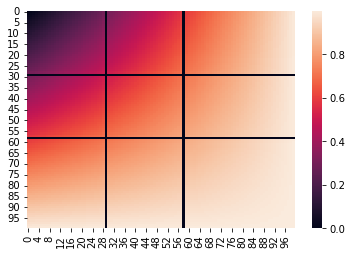

In [227]:
fig = plt.figure()

sns.heatmap(x)